### Task One 

In [14]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import nnfs

In [15]:
df=pd.read_csv('airbnb.csv')
df.head(3)


,listing_id,5_stars,availability_365,borough,host_id,host_name,is_rated,last_review,latitude,longitude,name,neighbourhood,number_of_reviews,number_of_stays,reviews_per_month,room_type,price,rating,listing_added
0,3831,0.757366,194,Brooklyn,4869,LisaRoxanne,1,2019-07-05,40.68514,-73.95976,Cozy Entire Floor of Brownstone,Clinton Hill,270,324.0,4.64,Entire place,89.0,3.273935,2018-12-30
1,6848,0.789743,46,Brooklyn,15991,Allen & Irina,1,2019-06-29,40.70837,-73.95352,Only 2 stops to Manhattan studio,Williamsburg,148,177.6,1.20,Entire place,140.0,3.495760,2018-12-24
2,7322,0.669873,12,Manhattan,18946,Doti,1,2019-07-01,40.74192,-73.99501,Chelsea Perfect,Chelsea,260,312.0,2.12,Private Room,140.0,4.389051,2018-12-26


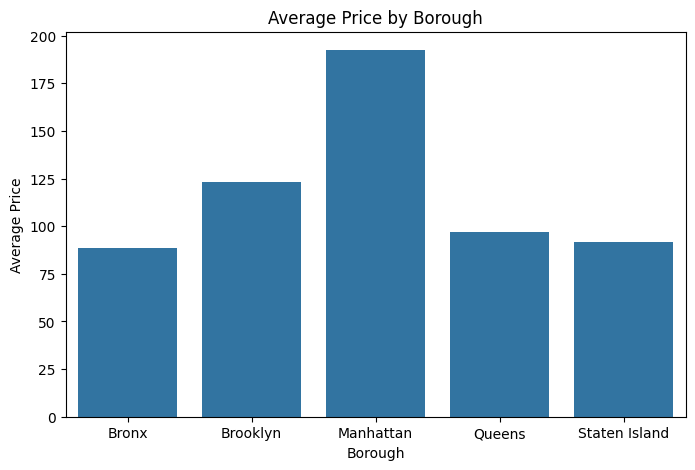

In [16]:
avg_price = df.groupby("borough", as_index=False)["price"].mean()

plt.figure(figsize=(8,5))
sns.barplot(x="borough", y="price", data=avg_price)
plt.title("Average Price by Borough")
plt.ylabel("Average Price")
plt.xlabel("Borough")
plt.show()

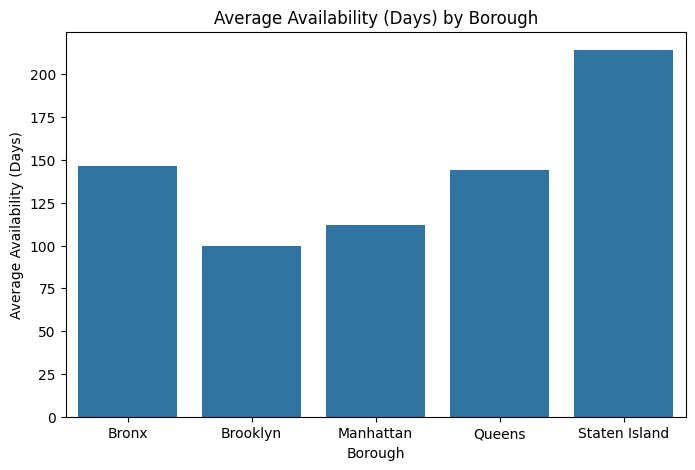

In [17]:
avg_availability = df.groupby("borough", as_index=False)["availability_365"].mean()

plt.figure(figsize=(8,5))
sns.barplot(x="borough", y="availability_365", data=avg_availability)
plt.title("Average Availability (Days) by Borough")
plt.ylabel("Average Availability (Days)")
plt.xlabel("Borough")
plt.show()

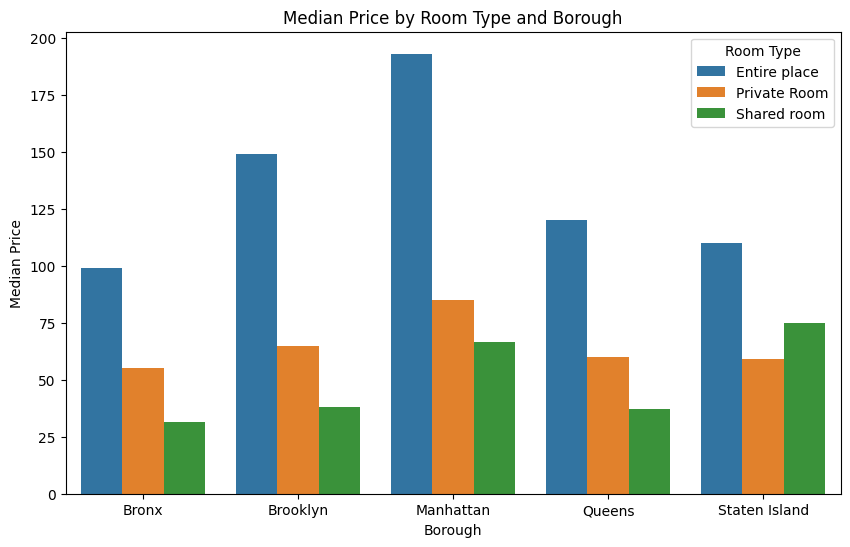

In [18]:
median_price = (
    df.groupby(["borough", "room_type"], as_index=False)["price"]
      .median()
)

plt.figure(figsize=(10,6))
sns.barplot(x="borough", y="price", hue="room_type", data=median_price)
plt.title("Median Price by Room Type and Borough")
plt.ylabel("Median Price")
plt.xlabel("Borough")
plt.legend(title="Room Type")
plt.show()

In [19]:
df["last_review"] = pd.to_datetime(df["last_review"])

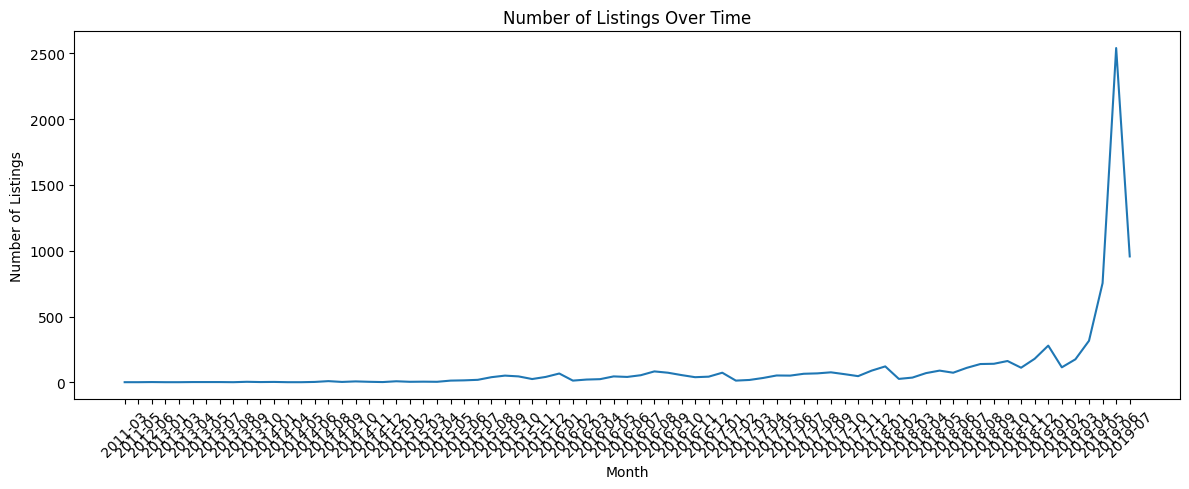

In [20]:
listings_over_time = (
    df.dropna(subset=["last_review"])
      .assign(month=df["last_review"].dt.strftime("%Y-%m"))
      .groupby("month")
      .size()
      .reset_index(name="num_listings")
)

plt.figure(figsize=(12,5))
sns.lineplot(x="month", y="num_listings", data=listings_over_time)
plt.title("Number of Listings Over Time")
plt.xlabel("Month")
plt.ylabel("Number of Listings")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Second Task

In [21]:
nnfs.init()

# ----------------------------
# Dense Layer
# ----------------------------
class Layer_Dense:
    def __init__(self, n_inputs, n_neurons):
        self.weights = 0.1 * np.random.randn(n_inputs, n_neurons)
        self.biases = np.zeros((1, n_neurons))

    def forward(self, inputs):
        self.output = np.dot(inputs, self.weights) + self.biases


# ----------------------------
# ReLU Activation
# ----------------------------
class Activation_ReLU:
    def forward(self, inputs):
        self.output = np.maximum(0, inputs)


# ----------------------------
# Softmax Activation
# ----------------------------
class Activation_Softmax:
    def forward(self, inputs):
        exp_values = np.exp(inputs - np.max(inputs, axis=1, keepdims=True))
        probabilities = exp_values / np.sum(exp_values, axis=1, keepdims=True)
        self.output = probabilities


# ----------------------------
# Read CSV
# ----------------------------
df = pd.read_csv("student_application_data.csv")

# Input features
X = df[["entrance_exam_score", "interview_score"]].values.astype(np.float32)

# Target labels
y = df["admission"].values

# ----------------------------
# Neural Network
# ----------------------------
dense1 = Layer_Dense(2, 5)
activation1 = Activation_ReLU()

dense2 = Layer_Dense(5, 2)
activation2 = Activation_Softmax()

# Forward Pass
dense1.forward(X)
activation1.forward(dense1.output)

dense2.forward(activation1.output)
activation2.forward(dense2.output)

print("Prediction Probabilities:")
print(activation2.output[:5])

predictions = np.argmax(activation2.output, axis=1)

# print("\nPredicted Classes:")
# print(predictions[:5])

# print("\nTrue Labels:")
# print(y[:5])

Prediction Probabilities:
[[0.5129321  0.4870679 ]
 [0.51316506 0.48683494]
 [0.5106028  0.4893972 ]
 [0.50904965 0.49095038]
 [0.5144847  0.4855153 ]]
